# Exploratory data analysis: 240,000 psychology journal articles from OpenAlex, 2001–2024

The project asks how the semantic breadth of research changes as a field publishes more, and how shifts in the mix of themes accompany that change. Breadth is measured as **knowledge extent (KE)**, the largest distance from a paper to the centre of a fixed-size sample of papers, in a document-embedding space (Hao et al., 2026).

This notebook explores the paper data that every later step uses. It covers the data's structure and size, the raw records, the features, the topic mix, data quality and preprocessing. It ends by turning a subset of papers into count vectors, TF-IDF vectors and embeddings. It does not compute KE, because the cleaning and model choices are fixed before the outcome is examined (`docs/decision_log.md`).

*Earlier related work.* `Week1_notebook.ipynb` compared distance metrics and token limits on a small sample, and `Week2_notebook.ipynb` chose the embedding model with a citation check. `exploratory_analysis.ipynb` tried the text representations of Section 7 on an 800-paper sample from all fields. Here they are repeated on psychology papers.

In [1]:
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer

from api_test import extract   # rebuilds abstracts from OpenAlex's word index
from src import embeddings     # the project's one embedding setup (SPECTER2, 512 tokens)
from src import theme_mix      # the exclusions applied before KE

POOL_DIR = Path("data/pool/psychology_field32")
TABLES, FIGURES = Path("outputs/tables"), Path("outputs/figures")
FLAGS = Path("data/eda/pool_flags.parquet")
for folder in (TABLES, FIGURES, FLAGS.parent):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 20261108  # example papers and the Section 6 subset

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]          # Week 2 chart colours
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

## 1. The dataset and its size

The data are journal articles from **OpenAlex**, an open catalogue of scholarly works. The field is **psychology**, meaning works whose *primary topic* lies in OpenAlex field 32, so each paper belongs to exactly one field. A paper is included if it is a journal article labelled English, is not front matter (`is_paratext:false`), has an abstract, and is in the curated core corpus.

For each year from 2001 to 2024, OpenAlex drew a seeded random sample of **10,000** such articles (`sample=10000&seed=1`). **One row is one article.** Later steps compute KE on equal-size draws of 1,000 papers per year, so a year with more papers cannot appear broader just because it is larger.

In [2]:
pool = pd.read_parquet(POOL_DIR / "pool.parquet")
meta = json.loads((POOL_DIR / "metadata.json").read_text())
print("OpenAlex filter:", meta["filter_template"], "| corpus:", meta["corpus"], "| seed:", meta["sample_seed"],
      "| pulled:", meta["created_at_utc"][:10])
print(f"{pool.shape[0]:,} rows x {pool.shape[1]} columns, {pool['publication_year'].min()}–{pool['publication_year'].max()}")
print("Papers per year:", pool.groupby("publication_year").size().unique())
print(f"{pool['primary_subfield'].nunique()} subfields, {pool['primary_topic'].nunique()} topics, {pool['source_id'].nunique():,} journals")

OpenAlex filter: primary_topic.field.id:32,type:article,language:en,is_paratext:false,primary_location.source.type:journal,has_abstract:true,publication_year:<year> | corpus: core | seed: 1 | pulled: 2026-10-25
240,000 rows x 23 columns, 2001–2024
Papers per year: [10000]
7 subfields, 141 topics, 28,426 journals


## 2. The raw data

OpenAlex returns each work as JSON, and it stores the abstract as an inverted index that maps each word to its positions. The pull rebuilds the text and flattens the record into one row. Below is the first raw record of 2001, then the rebuilt abstract, then a few rows of the flattened table.

In [3]:
page = json.loads((POOL_DIR / "raw/year=2001/seed=1/page_0001.json").read_text())
work = page["payload"]["results"][0]
print("title           :", work["title"])
print("year, type, lang:", work["publication_year"], work["type"], work["language"])
print("primary_topic   :", work["primary_topic"]["display_name"], "| score", round(work["primary_topic"]["score"], 3))
print("source          :", work["primary_location"]["source"]["display_name"])
print("abstract index  :", dict(list(work["abstract_inverted_index"].items())[:6]), "...")
rebuilt = extract.reconstruct_abstract(work["abstract_inverted_index"])
print("\nrebuilt abstract:", rebuilt[:600], "...")
print("\nmatches the pool row:", rebuilt == pool.loc[pool["openalex_id"] == work["id"], "abstract"].item())

title           : The Prevalence of Elevated Psychological Distress Among Canadian Undergraduates: Findings from the 1998 Canadian Campus Survey
year, type, lang: 2001 article en
primary_topic   : Student Stress and Coping | score 0.887
source          : Journal of American College Health
abstract index  : {'For': [0], 'a': [1, 13], 'study': [2], 'of': [3, 17, 38, 56, 64], 'elevated': [4, 45, 65], 'psychological': [5, 46]} ...

rebuilt abstract: For a study of elevated psychological distress, the authors used data based on a national probability sample of 7,800 Canadian undergraduate students from 16 universities. They used the 12-item General Health Questionnaire to assess mental health. Thirty percent of the students in the sample reported elevated psychological distress, which varied significantly according to sex, region, year of study, and recreational and academic orientation. Rates of elevated distress were significantly higher among the students than among the general populatio


matches the pool row: True


In [4]:
pd.set_option("display.max_colwidth", 60)
pool.sample(5, random_state=SEED)[["publication_year", "title", "abstract", "source_name", "primary_topic", "cited_by_count"]]

,publication_year,title,abstract,source_name,primary_topic,cited_by_count
215930,2022,Sexual and Gender Diverse Young Adults’ Perception of Be...,To explore specific responses that sexual and gender div...,Journal of Adolescent Research,"LGBTQ Health, Identity, and Policy",5
152408,2016,Development of social maturity: inter- and intra-subject...,Интер-и интрасубъектные факторы становления социальной з...,National Psychological Journal,Psychology of Development and Education,2
15659,2002,Creating Word Search Puzzles with a Pedagogical Purpose,Word search puzzles can be a fun way to add interest and...,Die Unterrichtspraxis/Teaching German,Educational Games and Gamification,1
217779,2022,A Family Education Intervention for Parents Having Child...,"During the COVID-19 pandemic, it has been observed that ...",International Journal of Contemporary Educational Research,Family and Disability Support Research,1
21653,2003,Effect of a pharmacological intervention on quality of l...,Patients with obsessive-compulsive disorder (OCD) not on...,International Clinical Psychopharmacology,Obsessive-Compulsive Spectrum Disorders,58


## 3. Features

The table lists the 23 columns with their type, number of distinct values, share missing, and role in the project.

In [5]:
KIND = {"title": "text", "abstract": "text", "publication_year": "numeric", "abstract_chars": "numeric",
        "primary_topic_score": "numeric", "cited_by_count": "numeric", "publication_date": "date",
        "primary_topic": "categorical", "primary_subfield": "categorical", "source_name": "categorical",
        "type": "constant", "language": "constant", "source_type": "constant", "primary_field": "constant",
        "primary_field_id": "constant", "source_seed": "constant", "sample_position": "provenance"}
ROLE = {"title": "model input", "abstract": "model input; KE and themes come from it",
        "publication_year": "defines the yearly samples", "abstract_chars": "quality checks",
        "primary_topic_score": "confidence of the topic label", "cited_by_count": "context only",
        "publication_date": "context only", "primary_topic": "topic panel unit (RQ1)",
        "primary_subfield": "fixed theme set (RQ2)", "source_name": "journal mix; junk checks",
        "source_seed": "OpenAlex sample seed (always 1)", "sample_position": "order in the OpenAlex sample"}
features = pd.DataFrame({
    "type": [KIND.get(c, "identifier") for c in pool.columns],
    "distinct": [pool[c].nunique() for c in pool.columns],
    "missing": pool.isna().mean().values,
    "role": [ROLE.get(c, "inclusion rule" if KIND.get(c) == "constant" else "key / link") for c in pool.columns],
}, index=pool.columns)
features.to_csv(TABLES / "eda_features.csv")
print(features["type"].value_counts().to_dict())
features.style.format({"distinct": "{:,}", "missing": "{:.1%}"})

{'identifier': 6, 'constant': 6, 'numeric': 4, 'categorical': 3, 'text': 2, 'date': 1, 'provenance': 1}


,type,distinct,missing,role
openalex_id,identifier,"240,000",0.0%,key / link
publication_year,numeric,24,0.0%,defines the yearly samples
doi,identifier,"208,213",13.2%,key / link
title,text,"238,632",0.0%,model input
abstract,text,"237,895",0.0%,model input; KE and themes come from it
abstract_chars,numeric,"6,300",0.0%,quality checks
publication_date,date,"8,253",0.0%,context only
type,constant,1,0.0%,inclusion rule
language,constant,1,0.0%,inclusion rule
primary_topic,categorical,141,0.0%,topic panel unit (RQ1)


Only the two **text** features, title and abstract, enter the embedding model, so KE, the themes and all distances come from them. **Publication year** defines the yearly samples. The **categorical** topic and subfield labels are the units for the two research questions. Topics are the units of the panel that relates growth to KE, and the seven subfields are a fixed set of themes for asking whether breadth changes within themes or through the mix. The **numeric** features serve as checks or context. Citation counts, for example, fall mechanically for recent papers, so they are not used as a measure. The six **constant** columns are inclusion rules or the single sample seed, so they carry no information inside the data. Missing values occur only in DOI (13%), ISSN (5%) and title (67 papers).

## 4. Distributions

### 4.1 Topics and subfields

Every year has the same 10,000 papers, so a topic's count in the pool shows its **share** of the year, not its volume.

In [6]:
topic_counts = pool["primary_topic"].value_counts()
print(f"{len(topic_counts)} topics; papers per topic: median {topic_counts.median():.0f}, "
      f"smallest {topic_counts.min()}, largest {topic_counts.max():,}; the 10 largest hold {topic_counts.head(10).sum() / len(pool):.0%}")
sub = pd.crosstab(pool["primary_subfield"], pool["publication_year"], normalize="columns")
pd.DataFrame({"papers": pool["primary_subfield"].value_counts(), "share 2001": sub[2001], "share 2024": sub[2024]}).style.format(
    {"papers": "{:,}", "share 2001": "{:.1%}", "share 2024": "{:.1%}"})

141 topics; papers per topic: median 1343, smallest 14, largest 6,667; the 10 largest hold 22%


,papers,share 2001,share 2024
primary_subfield,,,
Applied Psychology,"7,810",3.5%,3.0%
Clinical Psychology,"74,736",33.8%,28.9%
Developmental and Educational Psychology,"43,011",16.8%,21.3%
Experimental and Cognitive Psychology,"42,977",17.6%,17.3%
General Psychology,"1,495",1.2%,0.2%
Neuropsychology and Physiological Psychology,"2,900",1.5%,0.9%
Social Psychology,"67,071",25.6%,28.4%


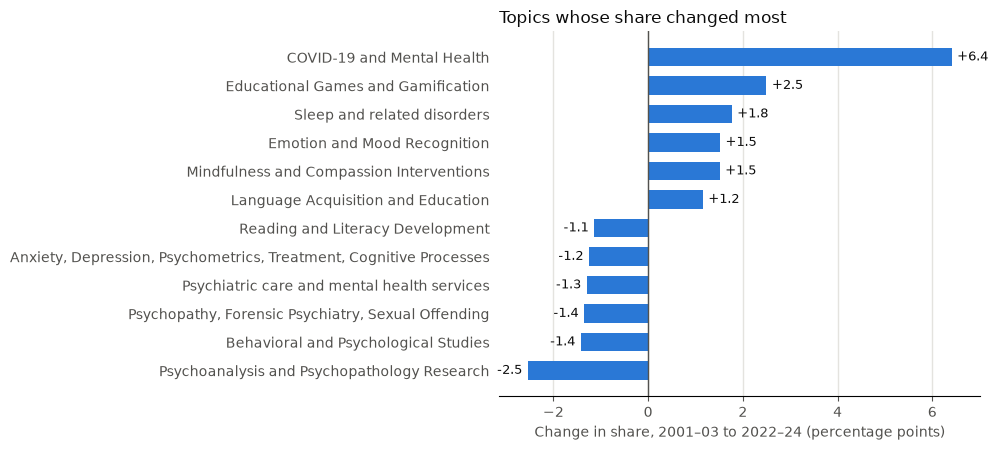

Topic shares changed by 31.9 percentage points in total (half the sum of absolute changes)
COVID-19 and Mental Health: 106 papers before 2020 (66 of them in 2003–05), 3,687 from 2020 on


In [7]:
window = pd.cut(pool["publication_year"], [2000, 2003, 2021, 2024], labels=["2001–03", "between", "2022–24"])
shares = pd.crosstab(pool["primary_topic"], window, normalize="columns")
change = ((shares["2022–24"] - shares["2001–03"]) * 100).sort_values()
movers = pd.concat([change.head(6), change.tail(6)])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(movers.index, movers.values, color=COLORS[0], height=0.65)
ax.axvline(0, color=MUTED, linewidth=1)
for y, value in enumerate(movers.values):
    ax.annotate(f"{value:+.1f}", (value, y), xytext=(4 if value > 0 else -4, 0), textcoords="offset points",
                ha="left" if value > 0 else "right", va="center", color=INK, fontsize=9)
ax.set_xlim(movers.min() - 0.6, movers.max() + 0.6)
ax.set_xlabel("Change in share, 2001–03 to 2022–24 (percentage points)", color=MUTED)
ax.set_title("Topics whose share changed most", color=INK, loc="left")
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, left=False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_topic_shares.png", dpi=200)
plt.show()
print(f"Topic shares changed by {abs(change).sum() / 2:.1f} percentage points in total (half the sum of absolute changes)")
covid = pool["primary_topic"] == "COVID-19 and Mental Health"
print(f"COVID-19 and Mental Health: {(covid & (pool['publication_year'] < 2020)).sum()} papers before 2020 "
      f"({(covid & pool['publication_year'].between(2003, 2005)).sum()} of them in 2003–05), "
      f"{(covid & (pool['publication_year'] >= 2020)).sum():,} from 2020 on")

The topic mix is uneven, from 14 papers in the smallest topic to 6,667 in the largest, and it moves. To turn the 2001–03 mix into the 2022–24 mix, about a third of the papers would have to change topic. The largest single gain is COVID-19 and mental health (+6.4 points), and among subfields clinical psychology loses share while developmental and educational psychology gains. Shifts like these are what the composition question (RQ2) measures. Because the field's centre moves with the mix, a growing topic can widen or narrow KE.

**Caveat.** The COVID-19 topic did not exist in 2001. OpenAlex labels the papers of every year with one present-day classifier and topic list, so older papers on related subjects also get the label. In the pool these are 106 papers before 2020, most of them on SARS in 2003–05, against 3,687 from 2020 on. Topic shares therefore describe today's categories applied backwards, not the categories researchers used at the time.

### 4.2 Abstract length

The embedding model reads text as tokens (words and word pieces) and ignores everything after 512 tokens. The counts below are for the exact model input, `title [SEP] abstract`, without truncation.

Characters per abstract: median 1084, 1st percentile 90, 99th 4474, max 27,602


Inputs over 512 tokens: 5.2% overall, 4.1%–7.2% by year


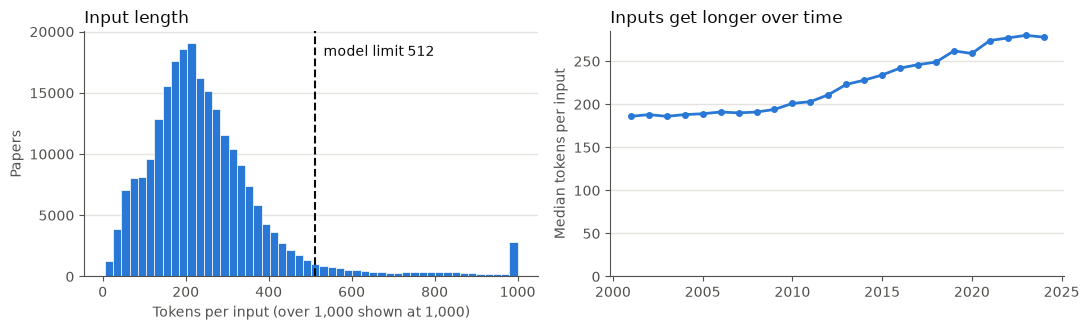

In [8]:
print(f"Characters per abstract: median {pool['abstract_chars'].median():.0f}, 1st percentile {pool['abstract_chars'].quantile(0.01):.0f}, "
      f"99th {pool['abstract_chars'].quantile(0.99):.0f}, max {pool['abstract_chars'].max():,}")
tokenizer = AutoTokenizer.from_pretrained(embeddings.MODELS["specter2_proximity"][0])
texts = [embeddings.input_text(t, a, tokenizer.sep_token) for t, a in zip(pool["title"], pool["abstract"])]
pool["tokens"] = embeddings.token_counts(tokenizer, texts)
by_year = pool.groupby("publication_year")["tokens"].agg(median="median", over_512=lambda n: (n > embeddings.MAX_TOKENS).mean())
print(f"Inputs over 512 tokens: {(pool['tokens'] > embeddings.MAX_TOKENS).mean():.1%} overall, "
      f"{by_year['over_512'].min():.1%}–{by_year['over_512'].max():.1%} by year")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.hist(pool["tokens"].clip(upper=1000), bins=50, color=COLORS[0], edgecolor="white", linewidth=0.5)
left.axvline(embeddings.MAX_TOKENS, color=INK, linewidth=1.5, linestyle="--")
left.annotate("model limit 512", (embeddings.MAX_TOKENS, left.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords="offset points", color=INK)
left.set_xlabel("Tokens per input (over 1,000 shown at 1,000)", color=MUTED)
left.set_ylabel("Papers", color=MUTED)
left.set_title("Input length", color=INK, loc="left")
right.plot(by_year.index, by_year["median"], color=COLORS[0], linewidth=2, marker="o", markersize=4)
right.set_ylim(bottom=0)
right.set_ylabel("Median tokens per input", color=MUTED)
right.set_title("Inputs get longer over time", color=INK, loc="left")
for ax in (left, right):
    style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "eda_tokens.png", dpi=200)
plt.show()

Abstracts grew longer over the period. At 512 tokens only a small and stable share of inputs is cut in every year, which is why the project truncates there (Week 2).

### 4.3 Journals

In [9]:
per_year = pool.groupby("publication_year")["source_id"].nunique()
print(f"Journals per year: {per_year[2001]:,} in 2001, {per_year[2024]:,} in 2024")
pool["source_name"].value_counts().head(6).rename("papers")

Journals per year: 2,477 in 2001, 5,459 in 2024


source_name
Frontiers in Psychology                                                   1827
PLoS ONE                                                                  1341
Proceedings of the Human Factors and Ergonomics Society Annual Meeting    1236
European Psychiatry                                                       1208
Psychiatric News                                                           917
Psychological Reports                                                      829
Name: papers, dtype: int64

No journal holds even 1% of the pool. Two of the largest sources are not ordinary research journals. *Psychiatric News* is a news magazine and the *Proceedings of the Human Factors and Ergonomics Society* are conference papers. Both come up again in Section 5.

## 5. Data quality

KE is a **maximum** distance, so a few junk texts in a sample (a website notice, a page of navigation links, an abstract in another language) can set a year's value. If the share of junk changes over time, it could create a KE trend unrelated to research. Each issue is therefore measured by year.

The non-English check is a simple rule fixed before any KE was computed. It flags a text when under half of its letters are ASCII (for example Chinese or Korean), or when it has at least 20 words of which under 10% are common English function words. English abstracts have a median of about 32% such words.

In [10]:
FUNCTION_WORDS = set("the of and to in a is that for with was were on as by this are we from be an or at which "
                     "these their it not between than".split())

def not_english_text(text):
    letters = [c for c in text if c.isalpha()]
    if sum(c.isascii() for c in letters) < 0.5 * len(letters):
        return True
    words = re.findall(r"[a-z]+", text.lower())
    return len(words) >= 20 and sum(w in FUNCTION_WORDS for w in words) < 0.10 * len(words)

normalized = pool["abstract"].str.lower().str.strip()
issues = pd.DataFrame({
    "missing title": pool["title"].fillna("").str.strip() == "",
    "shared abstract": normalized.duplicated(keep=False),
    "short (< 200 characters)": pool["abstract_chars"] < 200,
    "not English": pool["abstract"].map(not_english_text),
    "web-page text": pool["abstract"].str.contains(r"Back to table of contents|Previous article|Search for more papers"
                                                   r" by this author|Views Icon|No Access|Full Access", regex=True),
    "copyright text": pool["abstract"].str.contains(r"©|\(c\) ?\d{4}|copyright|all rights reserved", case=False, regex=True),
})
by_year = issues.groupby(pool["publication_year"]).mean()
by_year.to_csv(TABLES / "eda_quality_by_year.csv")
pd.DataFrame({"papers": issues.sum(), "share": issues.mean(), "2001": by_year.loc[2001], "2024": by_year.loc[2024]}).style.format(
    {"papers": "{:,}", "share": "{:.1%}", "2001": "{:.1%}", "2024": "{:.1%}"})

,papers,share,2001,2024
missing title,67,0.0%,0.0%,0.0%
shared abstract,"2,776",1.2%,2.1%,0.3%
short (< 200 characters),"8,585",3.6%,5.9%,1.6%
not English,"8,281",3.5%,1.8%,6.0%
web-page text,"1,431",0.6%,1.2%,0.0%
copyright text,"4,560",1.9%,3.1%,1.2%


In [11]:
repeated = normalized[issues["shared abstract"]].value_counts()
examples = [("shared abstract", f"{text[:80]} ({copies} copies)") for text, copies in repeated.head(2).items()]
for issue in ["short (< 200 characters)", "not English", "web-page text"]:
    texts = pool.loc[issues[issue], "abstract"].drop_duplicates()
    examples += [(issue, t[:100]) for t in texts.sample(2, random_state=SEED)]
pd.DataFrame(examples, columns=["issue", "abstract (first 100 characters)"]).style.hide(axis="index")

issue,abstract (first 100 characters)
shared abstract,frontiers events is a rapidly growing calendar management system dedicated to th (195 copies)
shared abstract,ammonsscientific.com is your first and best source for all of the information yo (128 copies)
short (< 200 characters),‫مسئول:‬ ‫نویسنده‬ ‫کمال‬
short (< 200 characters),"The Hematology of Anorexia Nervosa Nutrition Reviews, Volume 31, Issue 7, July 1973, Pages 207–209,"
not English,"이 연구는 과학고 및 영재학교 학생들의 발명과 창업에 대한 이미지 분석을 통하여, 향후 과학고 및 영재학교 학생들의 발명과 창업에 대한 이미지 개선을 위한 교육 및 지원의 시사점을"
not English,Epidemiološka istraživanja bilježe trend porasta teškoća mentalnog zdravlja kod djece i adolescenata
web-page text,Back to table of contents Previous article Next article Health Care EconomicsFull AccessDepression P
web-page text,No AccessPerspectives on School-Based IssuesArticle1 Mar 2004You Are Not Alone.com: Launching a Web


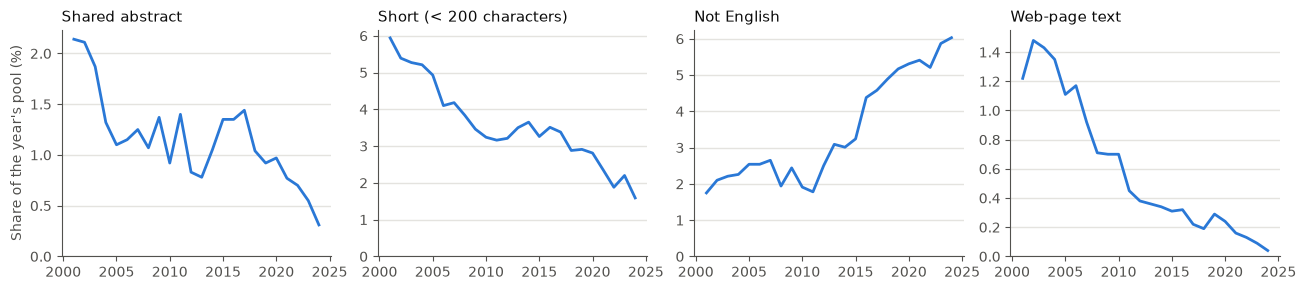

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=True)
for ax, issue in zip(axes, ["shared abstract", "short (< 200 characters)", "not English", "web-page text"]):
    ax.plot(by_year.index, by_year[issue] * 100, color=COLORS[0], linewidth=2)
    ax.set_ylim(bottom=0)
    ax.set_title(issue[0].upper() + issue[1:], color=INK, loc="left", fontsize=11)
    style_axes(ax)
axes[0].set_ylabel("Share of the year's pool (%)", color=MUTED)
fig.tight_layout()
fig.savefig(FIGURES / "eda_quality_by_year.png", dpi=200)
plt.show()

Repeated texts are either publisher boilerplate copied many times, such as the advert above, or duplicate records of the same article. Most short texts are citation strings, author lines, table notes or news teasers rather than abstracts. Web-page text comes almost entirely from *Psychiatric News*.

The issues move in **opposite directions**. Boilerplate, stubs and web pages are more common early, while non-English abstracts become more common late, so junk could make either end of the period look broader. Other checks found no further problems. The 240,000 OpenAlex IDs are unique, the topic label's confidence score has a stable median of 0.94–0.95 in every year, and very long abstracts are cut at 512 tokens anyway.

## 6. Preprocessing

| Step | What | Why |
|---|---|---|
| Inclusion | OpenAlex filters (article, journal, English label, not paratext, has abstract, primary topic in psychology) | Fixes the population before any outcome is seen |
| Abstract text | rebuilt from OpenAlex's word index; no other cleaning | Keeps the measure comparable with Hao et al. (2026) |
| Exclusions before KE | drop missing titles and abstracts shared with another paper | A missing title changes the model input, and shared texts are boilerplate or duplicate records |
| Flags | keep short, non-English and web-page texts, but flag them | No length or language rule removes junk without also removing real abstracts. The flags drive robustness checks (95th-percentile KE, inspecting the papers that set KE). |
| Model input | `title [SEP] abstract`, cut at 512 tokens; no lowercasing, stop-word removal or stemming | The transformer was trained on raw text and uses word order and function words |

The pool file itself stays unchanged at 10,000 papers per year. Exclusions and flags are stored separately, so other rules can be tried without a new download. No values are imputed. DOI and ISSN are not used, and papers without a title are dropped.

In [13]:
ke_eligible = theme_mix.ke_eligible(pool)
assert (ke_eligible == ~(issues["missing title"] | issues["shared abstract"])).all()
flags = pd.concat([pool[["openalex_id", "publication_year", "tokens"]], issues.add_prefix("flag: ")], axis=1)
flags["ke_eligible"] = ke_eligible
flags.to_parquet(FLAGS, index=False)
eligible = ke_eligible.groupby(pool["publication_year"]).sum()
print(f"Papers kept for KE: {ke_eligible.sum():,} of {len(pool):,} ({eligible.min():,}–{eligible.max():,} per year, "
      f"each far above the 1,000-paper draw)")

Papers kept for KE: 237,157 of 240,000 (9,782–9,969 per year, each far above the 1,000-paper draw)


## 7. Representing papers for analysis: a 1,200-paper subset

The full embedding run takes about four hours, so this section compares three representations on a seeded subset of **50 KE-eligible papers per year** (1,200 papers). They are the methods tried in `exploratory_analysis.ipynb`.

- **Count vectors.** One column per word, holding how often the word appears.
- **TF-IDF.** Count vectors reweighted so that words common across papers count less.
- **SPECTER2 embeddings.** 768 numbers per paper from a language model trained on scientific papers, which places papers that cite each other close together. This is the project's representation.

Count vectors and TF-IDF read the same title and abstract text, lowercased, with English stop words removed and words that occur in fewer than 5 papers dropped.

In [14]:
subset = pool[ke_eligible].groupby("publication_year", group_keys=False).sample(50, random_state=SEED).reset_index(drop=True)
docs = (subset["title"] + " " + subset["abstract"]).tolist()

counter = CountVectorizer(lowercase=True, stop_words="english", min_df=5, max_df=0.95)
X_count = counter.fit_transform(docs)
words = counter.get_feature_names_out()
print(f"Count vectors: {X_count.shape[0]:,} papers x {X_count.shape[1]:,} words, "
      f"{X_count.nnz / np.prod(X_count.shape):.1%} of cells non-zero")
print("Most frequent words:", ", ".join(words[np.argsort(-np.asarray(X_count.sum(axis=0)).ravel())[:15]]))

X_tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=5, max_df=0.95).fit_transform(docs)
i = 0
weights = X_tfidf[i].toarray().ravel()
print(f"\nTF-IDF, paper 0: {subset.loc[i, 'title']}")
print("Highest-weighted words:", ", ".join(f"{words[j]} {weights[j]:.2f}" for j in np.argsort(-weights)[:8]))

Count vectors: 1,200 papers x 3,434 words, 1.7% of cells non-zero
Most frequent words: study, students, health, results, research, self, mental, children, social, learning, group, based, used, using, patients

TF-IDF, paper 0: Being “the other therapist”: The varieties of adjunctive experience with hypnosis
Highest-weighted words: therapist 0.39, generating 0.23, utilize 0.22, approached 0.22, surprisingly 0.22, starting 0.21, currently 0.19, serve 0.19


In [15]:
model, model_tokenizer, info = embeddings.load("specter2_proximity")
start = time.time()
X_embed = embeddings.encode(model, model_tokenizer,
                            [embeddings.input_text(t, a, model_tokenizer.sep_token) for t, a in zip(subset["title"], subset["abstract"])])
print("Active adapter:", model.active_adapters, "(the warning above is printed while loading, before the adapter is switched on)")
print(f"SPECTER2: {X_embed.shape[0]:,} papers x {X_embed.shape[1]} dimensions in {time.time() - start:.0f} s on {info['device']} "
      f"(model revision {info['revision'][:10]}, adapter {info['adapter_revision'][:10]})")
print("Paper 0, first 8 dimensions:", np.round(X_embed[0, :8], 3))

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

There are adapters available but none are activated for the forward pass.


Active adapter: Stack[proximity] (the warning above is printed while loading, before the adapter is switched on)
SPECTER2: 1,200 papers x 768 dimensions in 60 s on mps (model revision 3447645e1d, adapter 2081559630)
Paper 0, first 8 dimensions: [ 0.541  0.937 -1.32  -0.043 -0.603 -0.231 -0.467 -0.163]


The TF-IDF example shows a weakness of word counts. Besides "therapist", the highest weights go to rare but uninformative words such as "surprisingly" and "utilize".

### Do the representations agree on which papers are similar?

For every paper, the next cell finds its 10 most similar papers under each representation by cosine similarity. The first table shows one example, and the second shows how often two representations pick the same neighbours.

In [16]:
K = 10
REPS = {"count vectors": X_count, "TF-IDF": X_tfidf, "SPECTER2": X_embed}

def neighbours(similarity, k=K):
    similarity = similarity.copy()
    np.fill_diagonal(similarity, -np.inf)
    return np.argsort(-similarity, axis=1)[:, :k]

NN = {name: neighbours(cosine_similarity(X)) for name, X in REPS.items()}
example = int(np.random.default_rng(SEED).integers(len(subset)))
print("Example:", subset.loc[example, "title"])
pd.DataFrame({name: subset.loc[nn[example, :3], "title"].str[:60].values for name, nn in NN.items()},
             index=["1st", "2nd", "3rd"])

Example: Using quality and accuracy ratings to quantify the value added of a dictionary skills training course


,count vectors,TF-IDF,SPECTER2
1st,Student collaboration skills post-implementation of the ...,THE USE OF «EDUTAINMENT» TECHNOLOGY IN THE COURSE OF TRA...,A Research into the Teaching Methods of English Words
2nd,THE USE OF «EDUTAINMENT» TECHNOLOGY IN THE COURSE OF TRA...,Student collaboration skills post-implementation of the ...,An Empirical Study of English Vocabulary Learning
3rd,PENINGKATAN KEMAMPUAN MEMBACA INTENSIF SISWA KELAS IV DE...,Teaching Language Training for Pre-school Education Majors,Using Keyword – Instruction on Developing Iraqi Intermed...


In [17]:
def overlap(a, b):
    # average share of the k neighbours that two representations have in common
    return np.mean([len(set(x) & set(y)) / K for x, y in zip(a, b)])

names = list(NN)
print("Share of the 10 nearest neighbours in common")
pd.DataFrame([[overlap(NN[a], NN[b]) for b in names] for a in names], index=names, columns=names).style.format("{:.2f}")

Share of the 10 nearest neighbours in common


,count vectors,TF-IDF,SPECTER2
count vectors,1.00,0.69,0.18
TF-IDF,0.69,1.00,0.21
SPECTER2,0.18,0.21,1.00


For this example, SPECTER2's neighbours are all about teaching vocabulary, while the word-count methods also pick papers that merely share words such as "course" and "training". Count vectors and TF-IDF largely agree with each other, and each agrees with SPECTER2 on only about a fifth of the neighbours.

Agreement alone does not say which representation is better, so the next cell checks the neighbours against OpenAlex's own labels. For each representation it shows how often a paper's 10 nearest neighbours share its topic and its subfield. The last row gives the rate for papers paired at random.

In [18]:
topic, subfield = subset["primary_topic"].to_numpy(), subset["primary_subfield"].to_numpy()
agreement = pd.DataFrame({name: {"same topic": (topic[nn] == topic[:, None]).mean(),
                                 "same subfield": (subfield[nn] == subfield[:, None]).mean()} for name, nn in NN.items()}).T
agreement.loc["random papers"] = [(subset["primary_topic"].value_counts(normalize=True) ** 2).sum(),
                                  (subset["primary_subfield"].value_counts(normalize=True) ** 2).sum()]
euclidean = neighbours(-pairwise_distances(X_embed))
print(f"SPECTER2 neighbours by Euclidean distance (the KE metric) vs cosine similarity: {overlap(euclidean, NN['SPECTER2']):.2f} in common")
agreement.style.format("{:.1%}")

SPECTER2 neighbours by Euclidean distance (the KE metric) vs cosine similarity: 0.96 in common


,same topic,same subfield
count vectors,20.4%,46.3%
TF-IDF,24.3%,49.2%
SPECTER2,31.1%,54.7%
random papers,1.3%,23.7%


SPECTER2's neighbours share the paper's topic most often, ahead of TF-IDF and count vectors, and all three are far above random pairs. OpenAlex's labels are imperfect, so this is a comparison between methods rather than an accuracy score. Euclidean and cosine neighbours almost coincide for SPECTER2, so the choice between the two distances matters little here.

## 8. Summary

- **Data.** 240,000 psychology journal articles with abstracts from OpenAlex, 10,000 per year for 2001–2024, with 23 columns. One row is one article.
- **Features.** Two text features (title and abstract) are the only model input. Year, topic and subfield organise the samples and the two research questions. Numeric columns are checks or context, and six columns are constant inclusion rules.
- **Topics.** There are 141 topics with a long tail, and their shares shift over two decades. This is the composition change that RQ2 measures.
- **Quality.** The main problems are boilerplate and duplicate abstracts, stubs, web pages and non-English abstracts. Their shares change over time in opposite directions, which matters because KE is a maximum.
- **Preprocessing.** Papers with a missing title or a shared abstract are dropped before KE, the other issues are flagged for robustness checks, and the model input is fixed at `title [SEP] abstract` with 512 tokens.
- **Representation.** On 1,200 papers, SPECTER2's neighbours share a paper's topic and subfield more often than the word-count methods' neighbours do, which supports using it for KE.